<a href="https://colab.research.google.com/github/Atika-Adelia/repo-gcolab-adel/blob/main/Modul_2_Transfer_Learning_dan_Strategi_Konvergensi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. Persiapan Data**

In [ ]:
# Library untuk penerapan deep learning berbasis pytorch
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms
# Library untuk visualisasi data
import matplotlib.pyplot as plt

In [ ]:
# Transformasi: Mengubah citra PIL menjadi Tensor dan meratakan nilai piksel (Normalisasi dasar 0-1)
transform = transforms.Compose([transforms.ToTensor()])

In [ ]:
# Memuat Dataset Fashion MNIST (Pakaian) untuk PRE-TRAINING
trainset_fashion = torchvision.datasets.FashionMNIST(root='./data', train=True,download=True, transform=transform)
trainloader_fashion = torch.utils.data.DataLoader(trainset_fashion, batch_size=256,shuffle=True)
# di dalam looping epoch ada looping batch (dimasukkin secara random)

In [ ]:
# Memuat Dataset MNIST (Angka Tulis Tangan) untuk FINE-TUNING
trainset_digit = torchvision.datasets.MNIST(root='./data', train=True, download=True,transform=transform)
testset_digit = torchvision.datasets.MNIST(root='./data', train=False, download=True,transform=transform)

trainloader_digit = torch.utils.data.DataLoader(trainset_digit, batch_size=256, shuffle=True)
testloader_digit = torch.utils.data.DataLoader(testset_digit, batch_size=256, shuffle=False)

print("Dataset berhasil dimuat!")

Dataset berhasil dimuat!


# **2. Arsitektur Model dengan Batch Normalization**

In [ ]:
class VisionMLP(nn.Module):
  def __init__(self):
    super(VisionMLP, self).__init__()
    # Input citra grayscale 28x28 piksel = 784 fitur 1D
    self.flatten = nn.Flatten()

    self.fc1 = nn.Linear(784, 256) # 784 ke 256
    self.bn1 = nn.BatchNorm1d(256) # Normalisasi Batch pada output layer 1

    self.fc2 = nn.Linear(256, 128)
    self.bn2 = nn.BatchNorm1d(128) # Normalisasi Batch pada output layer 2

    self.fc3 = nn.Linear(128, 10) # 10 Kelas output

    self.relu = nn.ReLU()

  def forward(self, x):
    x_flattened = self.flatten(x)

    # Urutan umum: Linear -> Batch Norm -> Activation
    net1 = self.relu(self.bn1(self.fc1(x_flattened)))
    net2 = self.relu(self.bn2(self.fc2(net1)))

    # Output logits
    net_out = self.fc3(net2)
    return net_out

In [ ]:
# Inisialisasi model dan kirim ke GPU jika tersedia
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_vision = VisionMLP().to(device)
print(f"Model dialokasikan pada: {device}")

Model dialokasikan pada: cuda


# **3. Pre-Training dan Penyimpanan Model**

In [ ]:
# Inisialisasi loss function (untuk multiclass), optimer dan jumlah epoch
criterion_vision = nn.CrossEntropyLoss() # menghitung loss nya
optimizer_vision = optim.Adam(model_vision.parameters(), lr=0.01) # memantau histori gradien sebelumnya
num_epochs = 5

In [ ]:
len(trainloader_fashion)

235

In [ ]:
# Proses pelatihan model dengan hanya melibatkan 5 epoch sebagai demonstrasi pre-training
print("--- Pre-Training pada Fashion MNIST ---")
model_vision.train() # karena setiap perubahannya tidak masuk ke mode eval

for epoch in range(num_epochs):
  running_loss = 0.0
  for images, labels in trainloader_fashion:
    images, labels = images.to(device), labels.to(device)

    optimizer_vision.zero_grad() # membersihkan komputasi graf nya
    outputs = model_vision(images)
    loss = criterion_vision(outputs, labels) # perhitungan loss
    loss.backward()
    optimizer_vision.step() # update bobot dengan model vision

    running_loss += loss.item()
  print(f"Pre-Train Epoch {epoch+1} | Loss: {running_loss/len(trainloader_fashion):.4f}")
print("Proses pelatihan model telah selesai dilakukan.")

--- Pre-Training pada Fashion MNIST ---
Pre-Train Epoch 1 | Loss: 0.4585
Pre-Train Epoch 2 | Loss: 0.3377
Pre-Train Epoch 3 | Loss: 0.2985
Pre-Train Epoch 4 | Loss: 0.2754
Pre-Train Epoch 5 | Loss: 0.2545
Proses pelatihan model telah selesai dilakukan.


In [ ]:
# Simpan bobot (pengetahuan) model
torch.save(model_vision.state_dict(), 'pretrained_fashion.pth')
print("Model berhasil disimpan ke 'pretrained_fashion.pth'")

Model berhasil disimpan ke 'pretrained_fashion.pth'


# **4. Fine-Tuning dengan LR Scheduler**

Pada proses sebelumnya telah dibuat model yang pintar mengenali pakaian, lalu "redirect" kepintarannya untuk mengenali angka.Pada tahap ini akan digunakan ReduceLROnPlateau Scheduler. Fitur ini memantau nilai Loss. Jika Loss berhenti menurun selama beberapa epoch (terjebak di dataran/plateau), Scheduler akan otomatis memperkecil Learning Rate agar algoritma melangkah lebih hati-hati (tidak melompati titik minimum global).

Set fine tuning arsitekturnya harus sama dengan sebelumnya, dimasukin modelnya baru dimodifikasi

Melakukan fine tuning semua layer (opsional)

In [ ]:
# Memuat kembali bobot pre-trained
transfer_model = VisionMLP().to(device)
transfer_model.load_state_dict(torch.load('pretrained_fashion.pth')) # load model yang sudah ditraining

# TRANSFER LEARNING:
# Mengganti (re-inisialisasi) lapisan terakhir (Head) untuk tugas spesifik yang baru
transfer_model.fc3 = nn.Linear(128, 10).to(device) #memodifikasi fc3

print(transfer_model)

VisionMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (bn1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)


In [ ]:
# Inisialisasi Optimizer dan Scheduler. Pada scheduler, Jika nilai validasi loss
# tidak turun dalam 2 epoch (patience=2), kurangi LR sebanyak faktor 0.1
optimizer_ft = optim.Adam(transfer_model.parameters(), lr=0.01)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer_ft, mode='min',factor=0.1, patience=2)

# Inisialisasi loss function, num of epoch, dan beberapa list
# untuk mencatat proses pelatihan
criterion_ft = nn.CrossEntropyLoss()
num_epochs_ft = 10 #fine tuning 10 epoch
ft_train_losses, ft_test_losses = [], []
ft_test_accs = []

In [ ]:
print("--- Fine-Tuning pada Digit MNIST ---")

for epoch in range(num_epochs_ft):
  # Tahap Training (pakai mini batch)
  transfer_model.train()
  train_loss = 0
  for images, labels in trainloader_digit:
    images, labels = images.to(device), labels.to(device)
    optimizer_ft.zero_grad()
    loss = criterion_ft(transfer_model(images), labels)
    loss.backward() #untuk mendapatkan delta
    optimizer_ft.step() # delta sebagai bahan update bobot
    train_loss += loss.item()
  avg_train_loss = train_loss / len(trainloader_digit)

  # Tahap Evaluasi
  transfer_model.eval()
  test_loss, correct, total = 0, 0, 0
  with torch.no_grad():

    for images, labels in testloader_digit:
      images, labels = images.to(device), labels.to(device)
      outputs = transfer_model(images)
      loss = criterion_ft(outputs, labels)
      test_loss += loss.item()

      # Mengambil prediksi probabilitas tertinggi (argmax)
      _, predicted = torch.max(outputs.data, 1) # mengambil nilai paling besar sebagai label prediktif
      total += labels.size(0) # menghitung jumlah label index ke-0
      correct += (predicted == labels).sum().item() # menghitung jumlah yang benar

  avg_test_loss = test_loss / len(testloader_digit)
  accuracy = correct / total

  ft_train_losses.append(avg_train_loss)
  ft_test_losses.append(avg_test_loss)
  ft_test_accs.append(accuracy)

  # Update Scheduler berdasarkan Validation Loss
  scheduler.step(avg_test_loss)
  print(f"Epoch {epoch+1:2d}")
  print(f"Train Loss: {avg_train_loss:.4f} | Test Loss: {avg_test_loss:.4f}")
  print(f"Test Acc: {accuracy*100:.2f}%")

--- Fine-Tuning pada Digit MNIST ---
Epoch  1
Train Loss: 0.2098 | Test Loss: 0.0871
Test Acc: 97.13%
Epoch  2
Train Loss: 0.0725 | Test Loss: 0.0621
Test Acc: 97.96%
Epoch  3
Train Loss: 0.0435 | Test Loss: 0.0707
Test Acc: 97.78%
Epoch  4
Train Loss: 0.0337 | Test Loss: 0.0733
Test Acc: 97.81%
Epoch  5
Train Loss: 0.0274 | Test Loss: 0.0653
Test Acc: 98.13%
Epoch  6
Train Loss: 0.0104 | Test Loss: 0.0502
Test Acc: 98.54%
Epoch  7
Train Loss: 0.0059 | Test Loss: 0.0483
Test Acc: 98.68%
Epoch  8
Train Loss: 0.0041 | Test Loss: 0.0492
Test Acc: 98.58%
Epoch  9
Train Loss: 0.0030 | Test Loss: 0.0483
Test Acc: 98.68%
Epoch 10
Train Loss: 0.0026 | Test Loss: 0.0491
Test Acc: 98.63%


# **5. Visualisasi Kinerja dan Inferensi Data Baru**

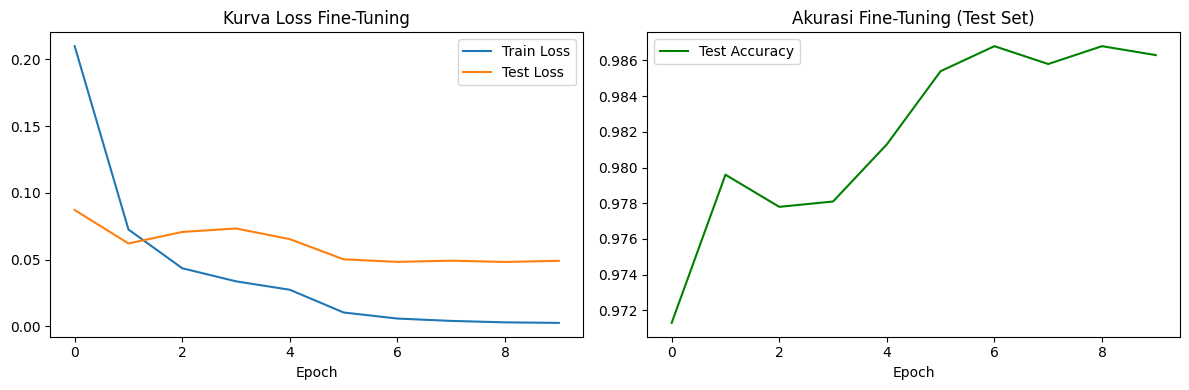

In [ ]:
# Plotting Loss & Accuracy
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(ft_train_losses, label='Train Loss')
plt.plot(ft_test_losses, label='Test Loss')
plt.title('Kurva Loss Fine-Tuning')
plt.xlabel('Epoch')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(ft_test_accs, color='green', label='Test Accuracy')
plt.title('Akurasi Fine-Tuning (Test Set)')
plt.xlabel('Epoch')
plt.legend()
plt.tight_layout()
plt.show()

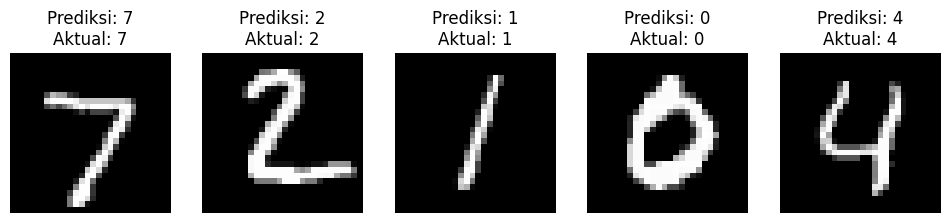

In [ ]:
# Contoh Inferensi (Pengujian pada data gambar nyata)
dataiter = iter(testloader_digit) # iter : mengambil 1 batch saja
images, labels = next(dataiter)

transfer_model.eval()
with torch.no_grad():
  outputs = transfer_model(images.to(device))
  _, preds = torch.max(outputs, 1)

# Menampilkan 5 gambar pertama beserta tebakan modelnya
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
  ax = axes[i]
  # squeeze untuk membuang dimensi channel (1, 28, 28) -> (28, 28)
  ax.imshow(images[i].squeeze(), cmap='gray')
  ax.set_title(f"Prediksi: {preds[i].item()}\nAktual: {labels[i].item()}")
  ax.axis('off')
plt.show()